# Urban Mobility Analysis and Trip Duration Prediction

**Dataset:** NYC Taxi Trip Duration (Kaggle) - random sample of 50,000 trips from 1,458,644 records

**Task:** Regression - predict `trip_duration` (in seconds) from trip distance, passenger count, pickup hour and day of week

**Model:** Linear Regression

## 1. Import Libraries

Load the libraries for data handling (`pandas`, `numpy`), plotting (`matplotlib`), model building (`LinearRegression`) and evaluation (MAE, MSE, R2).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load Data and Take a Random Sample

The full dataset has 1,458,644 trips. A random sample of 50,000 rows (`random_state=42` ) keeps the analysis fast also meaningful.

In [2]:
FILE_PATH = "NYC.csv"
SAMPLE_SIZE = 50000

df_full = pd.read_csv(FILE_PATH)
print(f"Full dataset shape: {df_full.shape}")

df = df_full.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print(f"Sampled dataset shape: {df.shape}")

Full dataset shape: (1458644, 11)
Sampled dataset shape: (50000, 11)


## 3. Data Cleaning

Remove records that are clearly errors:
- Trips shorter than 1 minute or longer than 3 hours (meter glitches)
- Trips whose pickup/dropoff coordinates fall outside the NYC bounding box (bad GPS readings)

Also convert the pickup/dropoff columns from text to datetime so time features can be extracted later.

In [3]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"])

before = len(df)
df = df[(df["trip_duration"] >= 60) & (df["trip_duration"] <= 3 * 3600)]
print(f"Removed {before - len(df)} rows with unrealistic trip_duration")

nyc_bounds = {"lon_min": -74.05, "lon_max": -73.70, "lat_min": 40.60, "lat_max": 40.90}
before = len(df)
df = df[
    df["pickup_longitude"].between(nyc_bounds["lon_min"], nyc_bounds["lon_max"]) &
    df["dropoff_longitude"].between(nyc_bounds["lon_min"], nyc_bounds["lon_max"]) &
    df["pickup_latitude"].between(nyc_bounds["lat_min"], nyc_bounds["lat_max"]) &
    df["dropoff_latitude"].between(nyc_bounds["lat_min"], nyc_bounds["lat_max"])
]
print(f"Removed {before - len(df)} rows with out-of-bounds coordinates")

df = df.reset_index(drop=True)
print(f"Final cleaned shape: {df.shape}")

Removed 409 rows with unrealistic trip_duration
Removed 186 rows with out-of-bounds coordinates
Final cleaned shape: (49405, 11)


## 4. Descriptive Statistics

Mean, median, mode, standard deviation, variance, min/max and quartiles for `passenger_count` and `trip_duration`, to understand the data before modelling.

In [4]:
numeric_cols = ["passenger_count", "trip_duration"]

for col in numeric_cols:
    print(f"\nColumn: {col}")
    print(f"  Mean     : {df[col].mean():.2f}")
    print(f"  Median   : {df[col].median():.2f}")
    print(f"  Mode     : {df[col].mode()[0]}")
    print(f"  Std Dev  : {df[col].std():.2f}")
    print(f"  Variance : {df[col].var():.2f}")
    print(f"  Min/Max  : {df[col].min()} / {df[col].max()}")
    print(f"  Q1/Q3    : {df[col].quantile(0.25):.2f} / {df[col].quantile(0.75):.2f}")

print("\nFull summary table:")
print(df[numeric_cols].describe())


Column: passenger_count
  Mean     : 1.67
  Median   : 1.00
  Mode     : 1
  Std Dev  : 1.32
  Variance : 1.73
  Min/Max  : 1 / 6
  Q1/Q3    : 1.00 / 2.00

Column: trip_duration
  Mean     : 838.77
  Median   : 663.00
  Mode     : 387
  Std Dev  : 650.66
  Variance : 423362.19
  Min/Max  : 60 / 9155
  Q1/Q3    : 400.00 / 1078.00

Full summary table:
       passenger_count  trip_duration
count     49405.000000   49405.000000
mean          1.669487     838.772088
std           1.316288     650.662885
min           1.000000      60.000000
25%           1.000000     400.000000
50%           1.000000     663.000000
75%           2.000000    1078.000000
max           6.000000    9155.000000


**Observation:** For `trip_duration` the mean (about 839 s) is higher than the median (663 s), so the distribution is right-skewed - most trips are short, while a few long trips pull the average up. The most common passenger count is 1 (solo riders).

## 5. Feature Engineering

The raw data has only GPS coordinates, so new features are created:
- `distance_km` - straight-line distance between pickup and dropoff using the Haversine formula (accounts for the curvature of the Earth)
- `pickup_hour` and `pickup_dayofweek` - extracted from the pickup timestamp, since traffic depends on when the trip happens

In [5]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

df["distance_km"] = haversine_distance(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_dayofweek"] = df["pickup_datetime"].dt.dayofweek

print(df["distance_km"].describe())

count    49405.000000
mean         3.400598
std          3.791771
min          0.000000
25%          1.244697
50%          2.095161
75%          3.874975
max         28.532868
Name: distance_km, dtype: float64


## 6. Correlation Analysis

Check how strongly each feature is related to `trip_duration`.

In [6]:
corr_cols = ["trip_duration", "distance_km", "passenger_count", "pickup_hour", "pickup_dayofweek"]
print(df[corr_cols].corr())

                  trip_duration  distance_km  passenger_count  pickup_hour  \
trip_duration          1.000000     0.766872         0.012660     0.025597   
distance_km            0.766872     1.000000         0.008387    -0.023333   
passenger_count        0.012660     0.008387         1.000000     0.010860   
pickup_hour            0.025597    -0.023333         0.010860     1.000000   
pickup_dayofweek      -0.033386     0.015406         0.027467    -0.079057   

                  pickup_dayofweek  
trip_duration            -0.033386  
distance_km               0.015406  
passenger_count           0.027467  
pickup_hour              -0.079057  
pickup_dayofweek          1.000000  


**Observation:** `distance_km` has a strong positive correlation with `trip_duration` (about 0.77). Passenger count, pickup hour and day of week show very weak individual correlations (close to 0).

## 7. Train-Test Split

Select the input features (X) and the target (y), then split the data 80% / 20%. The model learns from the training set (39,524 trips) and is evaluated on the unseen test set (9,881 trips).

In [7]:
features = ["distance_km", "passenger_count", "pickup_hour", "pickup_dayofweek"]
target = "trip_duration"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 39524, Test size: 9881


## 8. Build the Linear Regression Model and Regression Equation

Fit `LinearRegression` on the training data. The learned intercept and coefficients form the regression equation, and each coefficient shows how many seconds that feature adds to the predicted trip duration.

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})
print(coefficients)
print("Intercept =", model.intercept_)

equation = f"Trip_Duration = {model.intercept_:.2f}"
for feat, coef in zip(features, model.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.2f}({feat})"
print("\nRegression Equation:")
print(equation)

            Feature  Coefficient
0       distance_km   131.917054
1   passenger_count     3.355839
2       pickup_hour     4.025420
3  pickup_dayofweek   -14.174535
Intercept = 373.7417125152306

Regression Equation:
Trip_Duration = 373.74 + 131.92(distance_km) + 3.36(passenger_count) + 4.03(pickup_hour) - 14.17(pickup_dayofweek)


**Regression Equation:**

`Trip_Duration = 373.74 + 131.92(distance_km) + 3.36(passenger_count) + 4.03(pickup_hour) - 14.17(pickup_dayofweek)`

**Interpretation:** Every extra kilometre adds about 132 seconds (roughly 2.2 minutes) to the predicted trip duration. The other features have much smaller coefficients, so distance is the main driver.

## 9. Predict on Test Data and Evaluate

Predict trip durations for the test set (data the model has never seen) and compare with the actual values using:
- **MAE** - average absolute error in seconds
- **RMSE** - like MAE but penalises large errors more heavily
- **R2** - fraction of the variation in trip duration explained by the model (0 to 1)

In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f} seconds")
print(f"RMSE : {rmse:.2f} seconds")
print(f"R2   : {r2:.4f}")

MAE  : 284.11 seconds
RMSE : 414.16 seconds
R2   : 0.6045


**Interpretation:**
- MAE = 284.11 s, so predictions are off by about 4.7 minutes on average.
- RMSE = 414.16 s is higher than MAE, which means a few trips have large errors (typically the long trips).
- R2 = 0.6045, so the model explains about 60% of the variation in trip duration. The remainder depends on factors not in the data, such as live traffic and road conditions.

## 10. Actual vs Predicted Plot

Each point is one test trip. If predictions were perfect, every point would lie on the red dashed diagonal line.

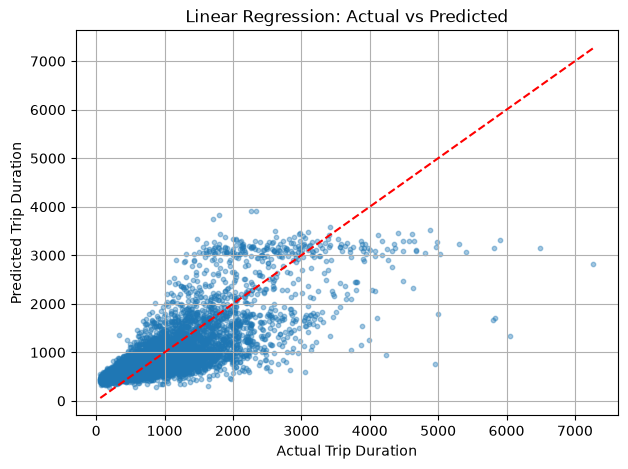

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.4, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Trip Duration")
plt.ylabel("Predicted Trip Duration")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()

## 11. Predict a New Trip

Use the trained model on a trip it has never seen: 5.2 km, 2 passengers, 6 PM (hour 18), Friday (day 4).

In [11]:
new_trip = pd.DataFrame({
    "distance_km": [5.2],
    "passenger_count": [2],
    "pickup_hour": [18],
    "pickup_dayofweek": [4]
})

predicted_duration = model.predict(new_trip)
print(f"Predicted trip duration: {predicted_duration[0]:.0f} seconds "
      f"(~{predicted_duration[0]/60:.1f} minutes)")

Predicted trip duration: 1082 seconds (~18.0 minutes)


**Result:** The model predicts about 18 minutes for this trip.

## Conclusion

A Linear Regression model trained on 50,000 NYC taxi trips predicts trip duration with an R2 of 0.60 and an average error of about 4.7 minutes. Trip distance is by far the most influential feature. The model gives a simple, fully interpretable equation, which makes it a good baseline for trip-duration (ETA) prediction.